# Lab 02 - Transformata Fouriera c.d.

### 1) wczytanie obrazu i jego normalizacja

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
script_dir = globals()['_dh'][0]
image_path = os.path.join(script_dir, 'lena.jpg')

img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
if img is None:
    print(f"Błąd: Nie znaleziono {image_path}")
    exit()

rows, cols = img.shape
img = img[:rows - (rows % 2), :cols - (cols % 2)]

img_float = np.float32(img) / 255.0

### 2) utworzenie zaszumionego obrazu

In [3]:
noise_size = int(0.05 * img_float.size)
random_indices = np.random.choice(img_float.size, noise_size)
noise = np.random.choice([0, 1], noise_size)
img_noisy = img_float.copy()
img_noisy.flat[random_indices] = noise

### 3) transformacja DCT

In [4]:
rows, cols = img_float.shape

In [5]:
dct_orig = cv2.dct(img_float)
dct_noisy = cv2.dct(img_noisy)

mask_dct = np.zeros((rows, cols), dtype=np.float32)
keep_rows_dct = int(rows * 0.15)
keep_cols_dct = int(cols * 0.15)
mask_dct[:keep_rows_dct, :keep_cols_dct] = 1

dct_q_orig = dct_orig * mask_dct
dct_q_noisy = dct_noisy * mask_dct

idct_orig = cv2.idct(dct_q_orig)
idct_noisy = cv2.idct(dct_q_noisy)

### 4) transformacja FFT

In [6]:
fft_orig = np.fft.fftshift(np.fft.fft2(img_float))
fft_noisy = np.fft.fftshift(np.fft.fft2(img_noisy))

mask_fft = np.zeros((rows, cols), dtype=np.float32)
center_row, center_col = rows // 2, cols // 2
r_rows, r_cols = int(rows * 0.075), int(cols * 0.075)

mask_fft[center_row - r_rows : center_row + r_rows, 
         center_col - r_cols : center_col + r_cols] = 1

fft_q_orig = fft_orig * mask_fft
fft_q_noisy = fft_noisy * mask_fft

ifft_orig = np.real(np.fft.ifft2(np.fft.ifftshift(fft_q_orig)))
ifft_noisy = np.real(np.fft.ifft2(np.fft.ifftshift(fft_q_noisy)))

### 5) wizualizacja

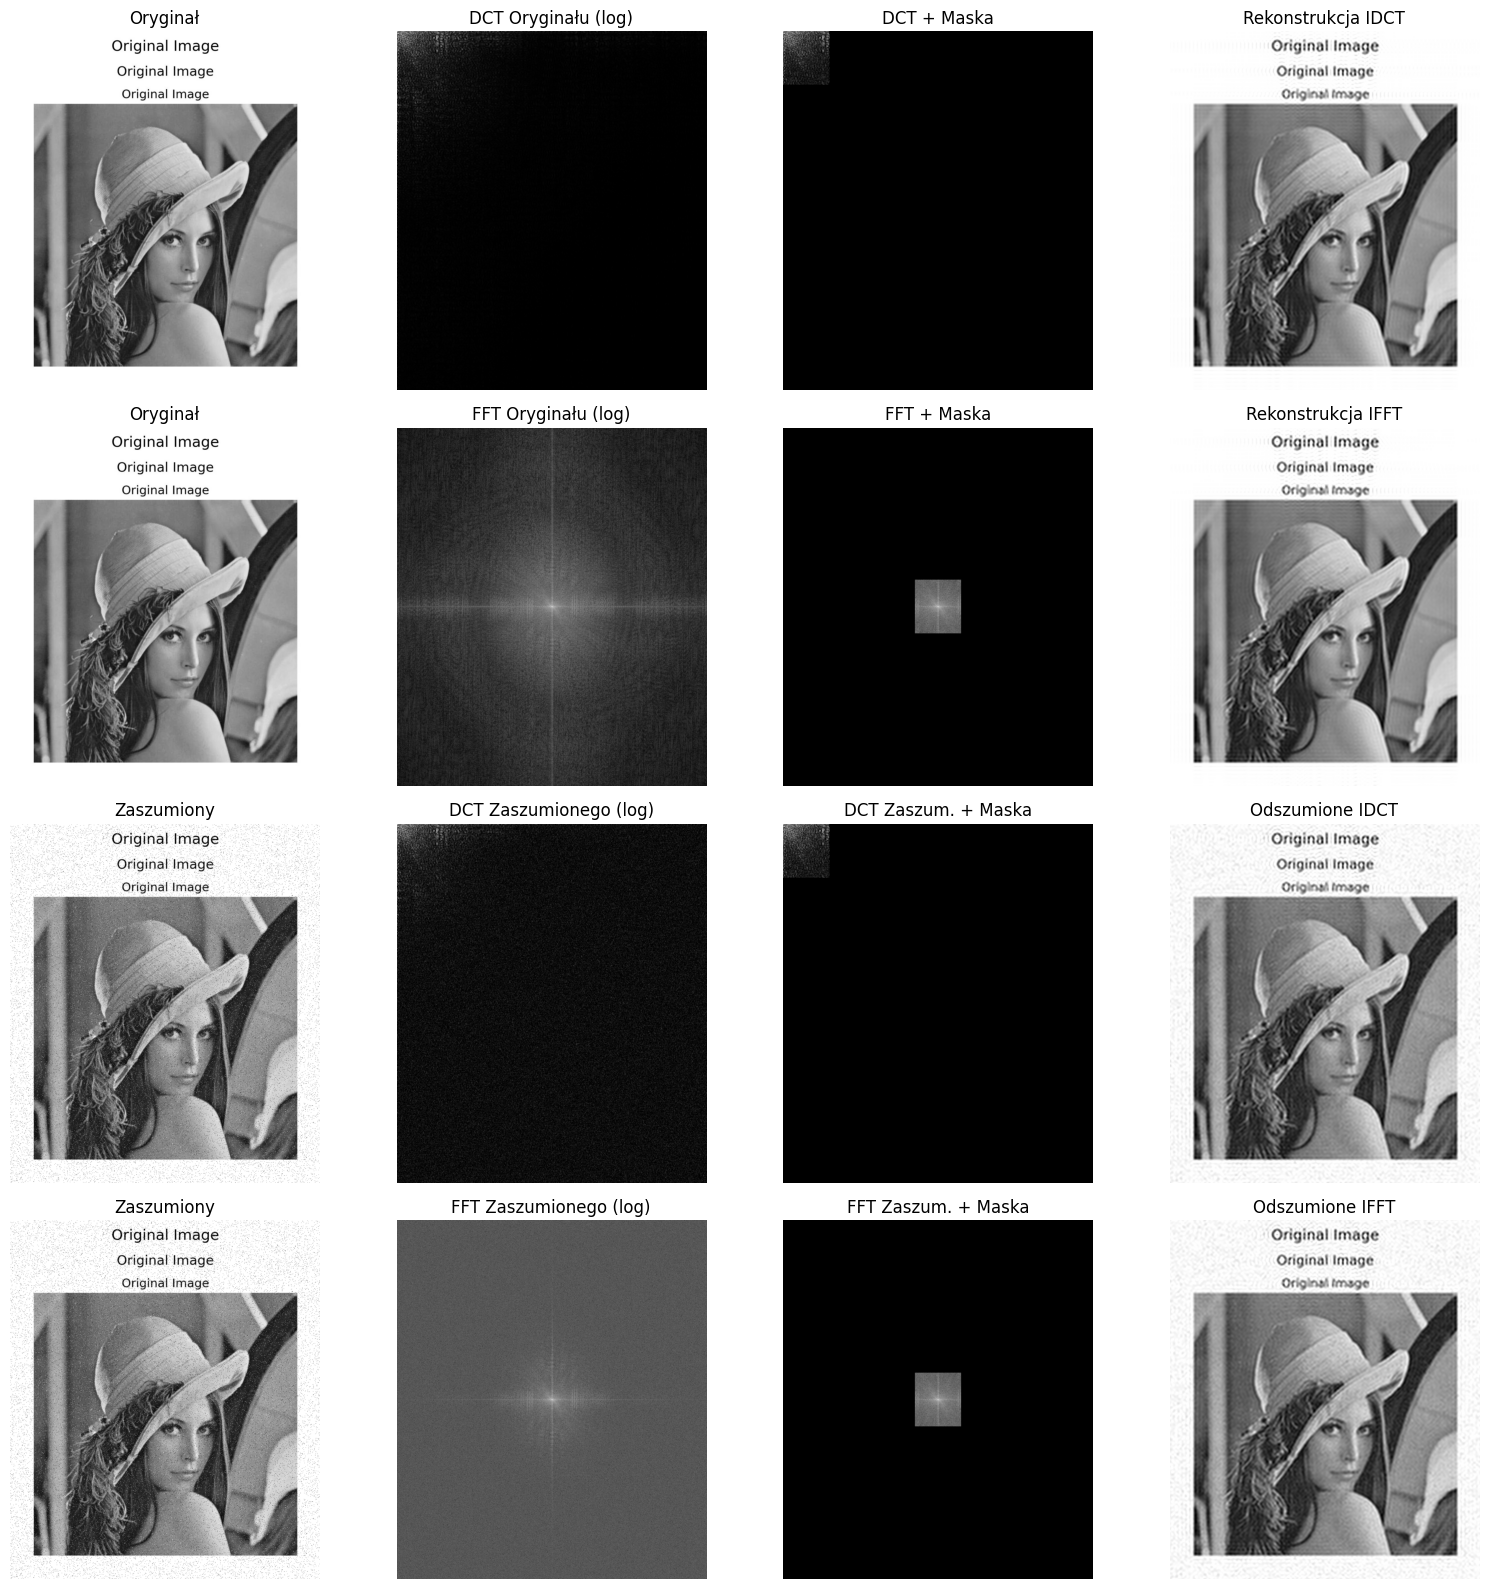

In [7]:
plt.figure(figsize=(16, 16))

def plot_img(position, image, title, is_log=False):
    plt.subplot(4, 4, position)
    plt.title(title)
    if is_log:
        plt.imshow(np.log(np.abs(image) + 1), cmap='gray')
    else:
        plt.imshow(image, cmap='gray', vmin=0.0, vmax=1.0)
    plt.axis('off')

# oryginał + DCT
plot_img(1, img_float, "Oryginał")
plot_img(2, dct_orig, "DCT Oryginału (log)")
plot_img(3, dct_q_orig, "DCT + Maska")
plot_img(4, idct_orig, "Rekonstrukcja IDCT")

# oryginał + FFT
plot_img(5, img_float, "Oryginał")
plot_img(6, fft_orig, "FFT Oryginału (log)", is_log=True)
plot_img(7, fft_q_orig, "FFT + Maska", is_log=True)
plot_img(8, ifft_orig, "Rekonstrukcja IFFT")

# zaszumiony + DCT
plot_img(9, img_noisy, "Zaszumiony")
plot_img(10, dct_noisy, "DCT Zaszumionego (log)")
plot_img(11, dct_q_noisy, "DCT Zaszum. + Maska")
plot_img(12, idct_noisy, "Odszumione IDCT")

# zaszumiony + FFT
plot_img(13, img_noisy, "Zaszumiony")
plot_img(14, fft_noisy, "FFT Zaszumionego (log)", is_log=True)
plot_img(15, fft_q_noisy, "FFT Zaszum. + Maska", is_log=True)
plot_img(16, ifft_noisy, "Odszumione IFFT")

plt.tight_layout()
plt.show()